In [2]:


import os
import numpy as np
import torch
from torch.utils.data import DataLoader, random_split
import matplotlib.pyplot as plt

from dendritic_modeling.synthetic_datasets import (
    LineDataset,
    CenterSurroundDataset,
    OrientationBarsDataset,
    MultiXORDataset,
    load_mnist_as_datasets,
    InfoShuntingDataset,
    NoisyLineDataset,
    SparseMNISTDataset,
    ContextualFigureGroundMNIST,
    MultiTaskLineDataset,
    CompositionalMNIST,
    get_unified_datasets
)
#



########################################
# Helper function: plot a single sample if 2D shape
########################################
def show_image_sample(flat_tensor, label, image_size=10):
    """
    Reshapes 'flat_tensor' into (image_size, image_size) 
    and shows it in a matplotlib figure with 'label' as title.
    """
    arr = flat_tensor.numpy().reshape(image_size, image_size)
    plt.imshow(arr, cmap='gray', vmin=0, vmax=1)
    plt.title(f"Label = {label}")
    plt.axis('off')
    plt.show()



## 1) LINE DATASET EXAMPLE ##
Sample 0 => label=2


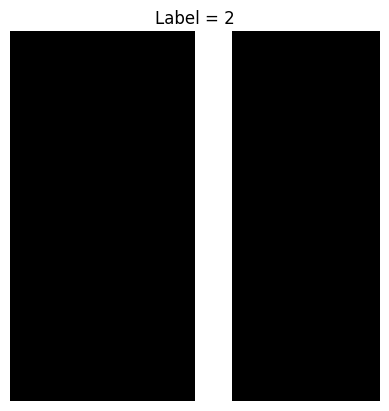

Sample 1 => label=1


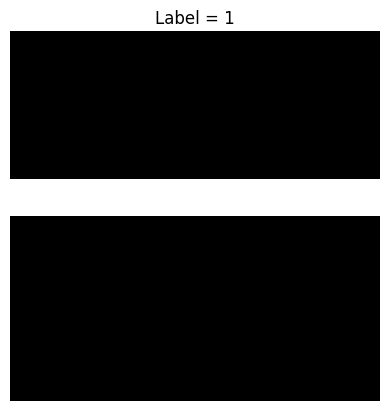

Sample 2 => label=2


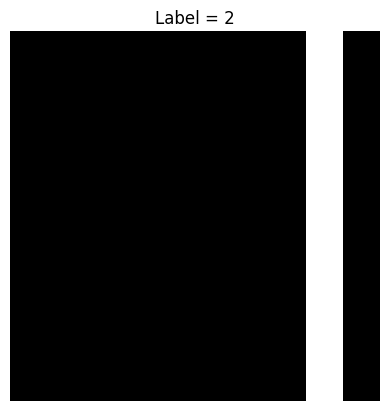


### Quick test: train on the line dataset ###


NameError: name 'SimpleMLP' is not defined

In [6]:

########################################
# 1) Demonstrate dataset usage: line
########################################
print("## 1) LINE DATASET EXAMPLE ##")
line_ds = LineDataset(n_samples=10, image_size=10)  # small sample
for i in range(3):
    x,y = line_ds[i]
    print(f"Sample {i} => label={y}")
    show_image_sample(x, y, image_size=10)



def train_simple_mlp(dataset, input_dim=100, output_dim=3, hidden_dim=50, epochs=5, batch_size=32):
    # We'll do a 80/20 split manually
    n_total = len(dataset)
    n_train = int(n_total*0.8)
    n_valid = n_total-n_train
    train_ds, valid_ds = random_split(dataset, [n_train, n_valid])

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    valid_loader = DataLoader(valid_ds, batch_size=batch_size, shuffle=False)

    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    model = SimpleMLP(input_dim, hidden_dim, output_dim).to(device)
    criterion = torch.nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

    for epoch in range(1, epochs+1):
        model.train()
        total_loss=0
        for xb,yb in train_loader:
            xb=xb.to(device)
            yb=yb.to(device)
            optimizer.zero_grad()
            out=model(xb)
            loss=criterion(out,yb)
            loss.backward()
            optimizer.step()
            total_loss+=loss.item()
        total_loss/=len(train_loader)

        # validation
        model.eval()
        val_loss=0
        correct=0
        total=0
        with torch.no_grad():
            for xb,yb in valid_loader:
                xb=xb.to(device)
                yb=yb.to(device)
                out=model(xb)
                loss=criterion(out,yb)
                val_loss+=loss.item()
                preds=out.argmax(dim=-1)
                correct+=(preds==yb).sum().item()
                total+=yb.size(0)
        val_loss/=len(valid_loader)
        acc=correct/total
        print(f"Epoch {epoch}/{epochs}, train_loss={total_loss:.4f}, val_loss={val_loss:.4f}, val_acc={acc:.3f}")

    return model


print("\n### Quick test: train on the line dataset ###")
line_ds_small = LineDataset(n_samples=500, image_size=10)
model = train_simple_mlp(line_ds_small, input_dim=10*10, output_dim=3, hidden_dim=50, epochs=5, batch_size=32)

print("Done. We can check final performance on entire line_ds_small.")


## 2) CENTER_SURROUND EXAMPLE ##
Sample 0 => label=1


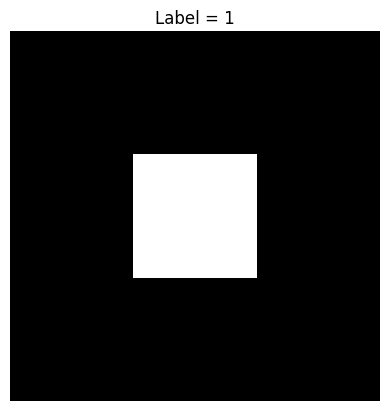

Sample 1 => label=1


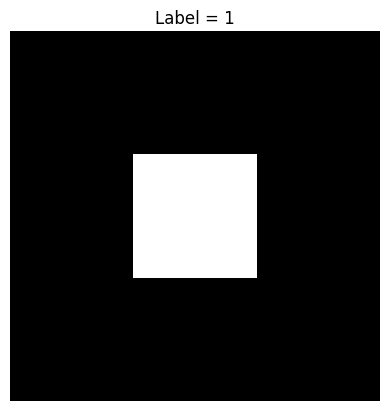

Sample 2 => label=2


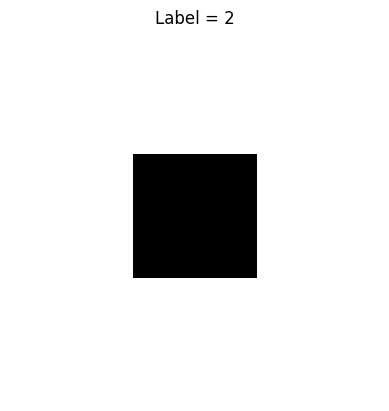

In [5]:

########################################
# 2) center_surround
########################################
print("## 2) CENTER_SURROUND EXAMPLE ##")
cs_ds = CenterSurroundDataset(n_samples=10, image_size=15)
for i in range(3):
    x,y = cs_ds[i]
    print(f"Sample {i} => label={y}")
    show_image_sample(x, y, image_size=15)



In [ ]:
########################################
# 3) orientation_bars
########################################
print("## 3) ORIENTATION_BARS EXAMPLE ##")
bars_ds = OrientationBarsDataset(n_samples=10, image_size=16, n_orient_classes=8)
for i in range(3):
    x,y = bars_ds[i]
    print(f"Sample {i} => orientation label={y}")
    show_image_sample(x, y, image_size=16)

########################################
# 4) multi_xor
########################################
print("## 4) MULTI_XOR EXAMPLE ##")
xor_ds = MultiXORDataset(n_samples=5, n_bits=8)
for i in range(5):
    x,y = xor_ds[i]
    print(f"bits = {x.numpy()}, label = {y}")

########################################
# 5) MNIST (load a small subset)
########################################
print("## 5) MNIST EXAMPLE ##")
train_ds, valid_ds, test_ds = load_mnist_as_datasets(train_valid_split=0.8)
print(f"Full MNIST train size = {len(train_ds)}")

# Let's show the first item 
x,y = train_ds[0]
print("Shape of x:", x.shape, "label:", y)


########################################
# 6) "New tasks" e.g. info_shunting
########################################
print("## 6) INFO_SHUNTING EXAMPLE ##")
info_ds = InfoShuntingDataset(n_samples=10, input_dim=10)
for i in range(5):
    x,y = info_ds[i]
    print(f"sample i={i}, x={x.numpy()}, label={y}")

########################################
# ... Similarly for NoisyLineDataset, etc.
########################################

print("\nNow let's do a small MLP training on a small dataset example (e.g. line dataset).")


########################################
# 7) Quick training example with a small MLP
########################################

class SimpleMLP(torch.nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super(SimpleMLP, self).__init__()
        self.net = torch.nn.Sequential(
            torch.nn.Linear(input_dim, hidden_dim),
            torch.nn.ReLU(),
            torch.nn.Linear(hidden_dim, output_dim)
        )
    def forward(self, x):
        return self.net(x)
    def predict(self, x):
        logits = self.forward(x)
        return logits.argmax(dim=-1)

def train_simple_mlp(dataset, input_dim=100, output_dim=3, hidden_dim=50, epochs=5, batch_size=32):
    # We'll do a 80/20 split manually
    n_total = len(dataset)
    n_train = int(n_total*0.8)
    n_valid = n_total-n_train
    train_ds, valid_ds = random_split(dataset, [n_train, n_valid])

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    valid_loader = DataLoader(valid_ds, batch_size=batch_size, shuffle=False)

    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    model = SimpleMLP(input_dim, hidden_dim, output_dim).to(device)
    criterion = torch.nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

    for epoch in range(1, epochs+1):
        model.train()
        total_loss=0
        for xb,yb in train_loader:
            xb=xb.to(device)
            yb=yb.to(device)
            optimizer.zero_grad()
            out=model(xb)
            loss=criterion(out,yb)
            loss.backward()
            optimizer.step()
            total_loss+=loss.item()
        total_loss/=len(train_loader)

        # validation
        model.eval()
        val_loss=0
        correct=0
        total=0
        with torch.no_grad():
            for xb,yb in valid_loader:
                xb=xb.to(device)
                yb=yb.to(device)
                out=model(xb)
                loss=criterion(out,yb)
                val_loss+=loss.item()
                preds=out.argmax(dim=-1)
                correct+=(preds==yb).sum().item()
                total+=yb.size(0)
        val_loss/=len(valid_loader)
        acc=correct/total
        print(f"Epoch {epoch}/{epochs}, train_loss={total_loss:.4f}, val_loss={val_loss:.4f}, val_acc={acc:.3f}")

    return model


print("\n### Quick test: train on the line dataset ###")
line_ds_small = LineDataset(n_samples=500, image_size=10)
model = train_simple_mlp(line_ds_small, input_dim=10*10, output_dim=3, hidden_dim=50, epochs=5, batch_size=32)

print("Done. We can check final performance on entire line_ds_small.")